# 自然言語処理システムの開発サイクル（文分割・データ分割・計算量・遠距離教師あり学習）

書籍 第1章「自然言語処理システムのデザイン」（1-3 データ：辞書やコーパス、1-4-2 データの分け方、1-4-3 計算量、1-5 開発サイクル、関連論文 1章 4）に対応する演習ノートブックです。
CPU のみ・数秒で実行でき、システム設計・運用の基盤となる 4 つのポイントを体験します。

1. **前処理 (1-5-1)**: 素朴な句点文分割が破綻するケース（「モーニング娘。」など）と例外処理
2. **データの分け方 (1-4-2)**: 訓練・開発・テストの役割とハイパーパラメータの選択に使ったデータで最終成績を報告したときの過大評価の実験
3. **計算量の実測（1-4-3, 表 1.1）**: $O(1)$（ハッシュ辞書）vs $O(n)$（線形探索）vs $O(n^2)$（全対比較）の実行時間スケーリング
4. **遠距離教師あり学習 (Distant Supervision)（1-3・関連論文 1章 4）**: 知識ベース (KB) の三つ組とラベルなしコーパスからの訓練データ自動構築、偶然共起ノイズ (False Positive) の分析、およびマルチインスタンス集約による関係抽出

In [1]:
!curl -fLO https://raw.githubusercontent.com/mamorlis/nlpbook/refs/heads/main/misc/covid-annotation.csv

In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

---

## 1. 前処理：文分割の落とし穴（1-5-1、p.42）

書籍 1-5-1 では、句点「。」だけで単純に文を分割すると**「モーニング娘。」のように句点が固有名詞に含まれている場合や、括弧・小数点・略語**で誤分割してしまうことが指摘されています。

In [3]:
def naive_split_sentences(text):
    return [s for s in text.split("。") if s.strip()]

def protected_split_sentences(text):
    # 固有名詞中の句点や括弧内の句点を保護して文分割する簡易例
    # （実運用では 3-2 の形態素解析を併用するのが確実です）
    protected_terms = ["モーニング娘。"]
    masked = text
    for i, term in enumerate(protected_terms):
        masked = masked.replace(term, f"__PROT_{i}__")

    # 括弧外の句点のみで分割
    out, buf, depth = [], [], 0
    for ch in masked:
        buf.append(ch)
        if ch in "（「(":
            depth += 1
        elif ch in "」）)" and depth > 0:
            depth -= 1
        elif ch == "。" and depth == 0:
            out.append("".join(buf).strip())
            buf = []
    if "".join(buf).strip():
        out.append("".join(buf).strip())

    restored = []
    for s in out:
        for i, term in enumerate(protected_terms):
            s = s.replace(f"__PROT_{i}__", term)
        restored.append(s)
    return restored

sample_text = (
    "彼女はモーニング娘。のファンです。"
    "ライブの感想をメモ（会場はとても熱気があった。音響も良い。）にまとめた。"
    "隣の家に住んでいるネコが寝込んだ。"
)

print("=== 素朴な句点分割（text.split('。')） ===")
for i, s in enumerate(naive_split_sentences(sample_text), 1):
    print(f"  {i}: {s}")

print("\n=== 固有名詞・括弧を考慮した文分割 ===")
for i, s in enumerate(protected_split_sentences(sample_text), 1):
    print(f"  {i}: {s}")

=== 素朴な句点分割（text.split('。')） ===
  1: 彼女はモーニング娘
  2: のファンです
  3: ライブの感想をメモ（会場はとても熱気があった
  4: 音響も良い
  5: ）にまとめた
  6: 隣の家に住んでいるネコが寝込んだ

=== 固有名詞・括弧を考慮した文分割 ===
  1: 彼女はモーニング娘。のファンです。
  2: ライブの感想をメモ（会場はとても熱気があった。音響も良い。）にまとめた。
  3: 隣の家に住んでいるネコが寝込んだ。


---

## 2. データの分け方：開発データ vs テストデータの役割（1-4-2、p.36〜37）

訓練データでモデルの重みを学習し、**開発データ (validation / dev data) でハイパーパラメータを選び、最終評価には開発時に一切触れていないテストデータ (test data) を使う**必要があります。
もし「小さな評価用データで一番スコアが高かった設定」をそのまま最終成績として報告してしまうと、見かけの精度が過大評価されます（**評価データへの過適合**）。`covid-annotation.csv`（1,000件）で確認してみましょう。

In [4]:
df = pd.read_csv("covid-annotation.csv")
df["y"] = (df["ラベル"] == True).astype(int)

# 訓練(160件) / 小規模な検証・選択用(60件) / 未知の最終テスト(780件) に分割
train_df, rest_df = train_test_split(df, train_size=160, stratify=df["y"], random_state=7)
select_df, final_test_df = train_test_split(rest_df, train_size=60, stratify=rest_df["y"], random_state=7)

candidates = [
    (ngram, min_df, C)
    for ngram in [(1, 1), (1, 2), (1, 3), (2, 3)]
    for min_df in [1, 2, 3]
    for C in [0.1, 0.5, 1.0, 3.0, 10.0, 30.0]
]

results = []
for ngram, min_df, C in candidates:
    pipe = make_pipeline(
        TfidfVectorizer(analyzer="char_wb", ngram_range=ngram, min_df=min_df),
        LogisticRegression(C=C, max_iter=1000),
    )
    pipe.fit(train_df["文書"], train_df["y"])
    acc_sel = accuracy_score(select_df["y"], pipe.predict(select_df["文書"]))
    acc_final = accuracy_score(final_test_df["y"], pipe.predict(final_test_df["文書"]))
    results.append({
        "ngram": ngram, "min_df": min_df, "C": C,
        "選択用データの正解率": acc_sel,
        "未知テスト(780件)の正解率": acc_final,
    })

res_df = pd.DataFrame(results).sort_values("選択用データの正解率", ascending=False)
print(f"探索した設定数: {len(res_df)} 通り")
display(res_df.head(5))

top1 = res_df.iloc[0]
print(
    f"選択用データ(60件)で最良だった設定: ngram={top1['ngram']}, min_df={top1['min_df']}, C={top1['C']}\n"
    f"  選択用データで見積もった正解率 : {top1['選択用データの正解率']:.3f} \n"
    f"  テストデータ(780件)での正解率 : {top1['未知テスト(780件)の正解率']:.3f}"
)

探索した設定数: 72 通り


,ngram,min_df,C,選択用データの正解率,未知テスト(780件)の正解率
58,"(2, 3)",1,10.0,0.950000,0.907692
59,"(2, 3)",1,30.0,0.950000,0.914103
40,"(1, 3)",1,10.0,0.933333,0.893590
41,"(1, 3)",1,30.0,0.933333,0.906410
56,"(2, 3)",1,1.0,0.933333,0.858974


選択用データ(60件)で最良だった設定: ngram=(2, 3), min_df=1, C=10.0
  選択用データで見積もった正解率 : 0.950 
  テストデータ(780件)での正解率 : 0.908


この実験では、選択用データ（60件）で最も正解率が高かった設定を選びます。その設定の正解率を、設定の選択に使った60件と、選択に使わなかった780件で比べてください。比較のため、このセルでは全候補のテスト正解率も計算しています。実際の開発では、開発データで設定を決めてから、選んだ設定だけをテストデータで評価します。テストの結果を見て設定をさらに変更する場合は、新たに独立したテストデータを用意します。

---

## 3. 計算量の実測：$O(1)$ vs $O(n)$ vs $O(n^2)$（1-4-3、表 1.1、p.37〜39）

書籍 1-4-3 では、処理時間を見積もる概念として **時間計算量（ビッグ・オー記法）** が解説されています。
データ数 $n$ を倍々 ($400 \to 800 \to 1600 \to 3200 \to 6400$) に増やしたとき、次の 3 つのアルゴリズムの実行時間がどう伸びるか実測してみましょう。

- **$O(1)$**: Python の `set`（ハッシュ表）による要素の有無の確認（平均）（300 クエリ検索）
- **$O(n)$**: Python の `list` による線形探索（300 クエリ検索）
- **$O(n^2)$**: 文書集合内の全ペア総当たり類似度計算（Transformer の自己注意や全対比較相当）

,n,O(1) set検索 [ms],O(n) list検索 [ms],O(n^2) 全ペア積 [ms]
0,400,0.013,0.626,0.256
1,800,0.021,2.332,0.585
2,1600,0.020,4.431,8.732
3,3200,0.357,9.308,19.135
4,6400,0.424,19.446,70.655


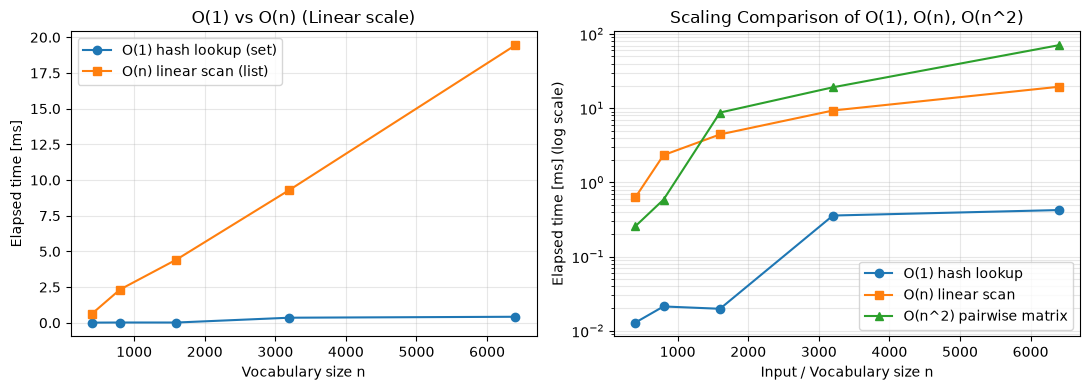

In [5]:
sizes = [400, 800, 1600, 3200, 6400]
rng = np.random.default_rng(0)
# BLAS 初期化の初回オーバーヘッドを除外するためのウォームアップ
_ = rng.random((256, 32), dtype=np.float32) @ rng.random((32, 256), dtype=np.float32)

bench = []
for n in sizes:
    vocab_list = [f"term_{i}" for i in range(n)]
    vocab_set = set(vocab_list)
    # 先頭・中央・末尾・未登録語を混ぜて、n に比例した探索距離になるクエリを作る
    hit_queries = [vocab_list[i] for i in np.linspace(0, n - 1, 150, dtype=int)]
    miss_queries = [f"missing_{i}" for i in range(150)]
    queries = hit_queries + miss_queries

    # O(1): ハッシュ検索 × 300クエリ
    t0 = time.perf_counter()
    _ = sum(q in vocab_set for q in queries)
    t_o1 = (time.perf_counter() - t0) * 1000

    # O(n): リスト線形探索 × 300クエリ
    t0 = time.perf_counter()
    _ = sum(q in vocab_list for q in queries)
    t_on = (time.perf_counter() - t0) * 1000

    # O(n^2): n × n の内積計算（全ペア比較）
    vecs = rng.random((n, 32), dtype=np.float32)
    t0 = time.perf_counter()
    _ = vecs @ vecs.T
    t_on2 = (time.perf_counter() - t0) * 1000

    bench.append({
        "n": n,
        "O(1) set検索 [ms]": t_o1,
        "O(n) list検索 [ms]": t_on,
        "O(n^2) 全ペア積 [ms]": t_on2,
    })

df_bench = pd.DataFrame(bench)
display(df_bench.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(df_bench["n"], df_bench["O(1) set検索 [ms]"], marker="o", label="O(1) hash lookup (set)")
axes[0].plot(df_bench["n"], df_bench["O(n) list検索 [ms]"], marker="s", label="O(n) linear scan (list)")
axes[0].set_xlabel("Vocabulary size n")
axes[0].set_ylabel("Elapsed time [ms]")
axes[0].set_title("O(1) vs O(n) (Linear scale)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(df_bench["n"], df_bench["O(1) set検索 [ms]"], marker="o", label="O(1) hash lookup")
axes[1].plot(df_bench["n"], df_bench["O(n) list検索 [ms]"], marker="s", label="O(n) linear scan")
axes[1].plot(df_bench["n"], df_bench["O(n^2) 全ペア積 [ms]"], marker="^", label="O(n^2) pairwise matrix")
axes[1].set_yscale("log")
axes[1].set_xlabel("Input / Vocabulary size n")
axes[1].set_ylabel("Elapsed time [ms] (log scale)")
axes[1].set_title("Scaling Comparison of O(1), O(n), O(n^2)")
axes[1].legend()
axes[1].grid(alpha=0.3, which="both")

plt.tight_layout()
plt.show()

---

## 4. 遠距離教師あり学習 (Distant Supervision) による訓練データの自動構築とノイズ分析（1-3・関連論文 1章 4）

書籍 1-3「データ：辞書やコーパス」および関連論文 1章 4（Mintz et al., ACL 2009「*Distant supervision for relation extraction without labeled data*」）では、人手で文ごとに正解ラベルを付ける代わりに、既存の知識ベース (KB) とラベルなしテキストを突き合わせて訓練データを自動構築する **遠距離教師あり学習 (Distant Supervision)** が紹介されています。

Distant Supervision の基本仮定は次のとおりです。

> 知識ベース (KB) に登録された 2 つのエンティティ $(e_1, e_2)$ が関係 $r$ を持つとき、**その 2 エンティティが共起する文はすべて関係 $r$ を表している**とみなす（KB に登録のないペアの共起文は負例 `NA` とする）。

この規則により大量の訓練データを低コストで用意できる一方、実際には関係 $r$ を表していない**偶然共起のノイズ (False Positive)** が混入します。まずは KB（3 関係・15 組）とラベルなし日本語コーパス（36 文）を用意し、自動ラベル付けでどれほどノイズが入るか確認しましょう。

In [6]:
import re
from collections import Counter, defaultdict
from sklearn.metrics import precision_recall_fscore_support
from sklearn.pipeline import FeatureUnion

# 1. 知識ベース (KB) の三つ組: (主語エンティティ, 関係ラベル, 目的語エンティティ)
kb_triples = [
    ("明光電機", "本社所在地", "東京都"),
    ("北陸製薬", "本社所在地", "富山県"),
    ("瀬戸内造船", "本社所在地", "広島県"),
    ("信濃精密", "本社所在地", "長野県"),
    ("九州食品", "本社所在地", "福岡県"),
    ("光速DB", "開発元", "青葉ソフト"),
    ("星雲翻訳", "開発元", "銀河AI研"),
    ("匠CAD", "開発元", "大和技研"),
    ("彩り解析", "開発元", "風車ラボ"),
    ("隼サーチ", "開発元", "東雲システム"),
    ("蒼穹大学", "キャンパス所在地", "宮城県"),
    ("若葉学院大学", "キャンパス所在地", "愛知県"),
    ("碧海工科大学", "キャンパス所在地", "兵庫県"),
    ("白樺女子大学", "キャンパス所在地", "北海道"),
    ("南風理科大学", "キャンパス所在地", "沖縄県"),
]
kb_map = {(s, o): r for s, r, o in kb_triples}
kb_entities = sorted({s for s, _, _ in kb_triples} | {o for _, _, o in kb_triples}, key=len, reverse=True)

# 2. ラベルなし日本語コーパス（36文; 第2要素の gold_for_audit は事後のノイズ監査専用であり学習には一切使わない）
raw_corpus = [
    # 本社所在地: 関係を表す文 (6)
    ("明光電機は東京都に本社を置く総合メーカーです。", "本社所在地"),
    ("北陸製薬の本社所在地は富山県にあり、研究棟を併設する。", "本社所在地"),
    ("広島県に本社を構える瀬戸内造船は新型貨物船を受注した。", "本社所在地"),
    ("信濃精密は長野県に本社を置く精密部品メーカーだ。", "本社所在地"),
    ("福岡県に本社を置く九州食品は地元食材の商品開発を進める。", "本社所在地"),
    ("東京都に本社を構える明光電機が省エネ家電を発表した。", "本社所在地"),
    # 本社所在地: 偶然共起ノイズ文 (2)
    ("明光電機は東京都で開かれた国際見本市に試作品を展示した。", "NA"),
    ("北陸製薬は富山県内の地域清掃ボランティアに協力した。", "NA"),
    # 開発元: 関係を表す文 (6)
    ("光速DBは青葉ソフトが開発した高速データベース基盤です。", "開発元"),
    ("銀河AI研が開発を手がけた星雲翻訳は専門文書の訳質が高い。", "開発元"),
    ("大和技研が開発した匠CADは設計工程を大幅に短縮する。", "開発元"),
    ("風車ラボが開発を手がけた彩り解析はテキスト感情を可視化する。", "開発元"),
    ("東雲システムが開発した隼サーチは全文検索を高速化する。", "開発元"),
    ("青葉ソフトが開発した光速DBが金融機関へ広く普及した。", "開発元"),
    # 開発元: 偶然共起ノイズ文 (2)
    ("青葉ソフトの社内交流会で光速DBに関するクイズが出題された。", "NA"),
    ("銀河AI研の創立記念イベントで星雲翻訳の記念品が配られた。", "NA"),
    # キャンパス所在地: 関係を表す文 (6)
    ("蒼穹大学は宮城県にキャンパスを構える総合大学です。", "キャンパス所在地"),
    ("愛知県にキャンパスを置く若葉学院大学では地域連携が進む。", "キャンパス所在地"),
    ("兵庫県にキャンパスを構える碧海工科大学は海事研究で知られる。", "キャンパス所在地"),
    ("白樺女子大学は北海道に広大なキャンパスを置く女子大学だ。", "キャンパス所在地"),
    ("沖縄県にキャンパスを構える南風理科大学が新設学部を開いた。", "キャンパス所在地"),
    ("宮城県にある蒼穹大学のキャンパスで学園祭が実施された。", "キャンパス所在地"),
    # キャンパス所在地: 偶然共起ノイズ文 (2)
    ("蒼穹大学の吹奏楽団が宮城県のコンクールで金賞を受けた。", "NA"),
    ("白樺女子大学は北海道の観光協会と防災企画を共催した。", "NA"),
    # KB 上に関係がないエンティティ対の共起文 (12)
    ("明光電機は福岡県で新製品の展示会を開いた。", "NA"),
    ("蒼穹大学は青葉ソフトと共同研究契約を結んだ。", "NA"),
    ("北陸製薬は愛知県に新しい営業所を開設した。", "NA"),
    ("大和技研は東京都で技術カンファレンスを開催した。", "NA"),
    ("隼サーチは広島県の自治体システムへ導入された。", "NA"),
    ("九州食品は宮城県の物産フェアに協賛している。", "NA"),
    ("風車ラボと碧海工科大学は人材育成で連携協定を結んだ。", "NA"),
    ("信濃精密は北海道の産業展へ最新センサーを出展した。", "NA"),
    ("銀河AI研は沖縄県で夏季合宿の勉強会を実施した。", "NA"),
    ("瀬戸内造船の製品説明会が長野県の会場で開かれた。", "NA"),
    ("星雲翻訳は富山県の病院案内システムで試験採用された。", "NA"),
    ("若葉学院大学は東雲システムの検索基盤を授業で活用する。", "NA"),
]

def find_entity_pair(text, entities):
    found = [(text.find(e), e) for e in entities if e in text]
    found.sort()
    assert len(found) == 2, f"Unexpected entity count in: {text}"
    return found[0][1], found[1][1]

def assign_ds_label(e1, e2):
    if (e1, e2) in kb_map:
        return kb_map[(e1, e2)]
    if (e2, e1) in kb_map:
        return kb_map[(e2, e1)]
    return "NA"

ds_rows = []
for text, gold_audit in raw_corpus:
    e1, e2 = find_entity_pair(text, kb_entities)
    ds_lbl = assign_ds_label(e1, e2)
    is_fp = (ds_lbl != "NA") and (gold_audit == "NA")
    ds_rows.append({
        "文": text,
        "エンティティ1": e1,
        "エンティティ2": e2,
        "DS自動ラベル": ds_lbl,
        "実際の関係(監査用)": gold_audit,
        "ノイズ(FP)": is_fp,
    })

ds_df = pd.DataFrame(ds_rows)
print("KB 三つ組数:", len(kb_triples), "/ ラベルなしコーパス文数:", len(ds_df))
print("DS 自動ラベル内訳:", dict(Counter(ds_df["DS自動ラベル"])))
n_pos_ds = int((ds_df["DS自動ラベル"] != "NA").sum())
n_fp_ds = int(ds_df["ノイズ(FP)"].sum())
print(f"正例と自動ラベル付けされた {n_pos_ds} 文のうち偶然共起ノイズ (False Positive): {n_fp_ds} 文 ({n_fp_ds / n_pos_ds:.1%})")
print("\n=== 自動ラベルに混入した偶然共起ノイズ (False Positive) の例 ===")
display(ds_df[ds_df["ノイズ(FP)"]][["エンティティ1", "エンティティ2", "DS自動ラベル", "実際の関係(監査用)", "文"]])

KB 三つ組数: 15 / ラベルなしコーパス文数: 36
DS 自動ラベル内訳: {'本社所在地': 8, '開発元': 8, 'キャンパス所在地': 8, 'NA': 12}
正例と自動ラベル付けされた 24 文のうち偶然共起ノイズ (False Positive): 6 文 (25.0%)

=== 自動ラベルに混入した偶然共起ノイズ (False Positive) の例 ===


,エンティティ1,エンティティ2,DS自動ラベル,実際の関係(監査用),文
6,明光電機,東京都,本社所在地,NA,明光電機は東京都で開かれた国際見本市に試作品を展示した。
7,北陸製薬,富山県,本社所在地,NA,北陸製薬は富山県内の地域清掃ボランティアに協力した。
14,青葉ソフト,光速DB,開発元,NA,青葉ソフトの社内交流会で光速DBに関するクイズが出題された。
15,銀河AI研,星雲翻訳,開発元,NA,銀河AI研の創立記念イベントで星雲翻訳の記念品が配られた。
22,蒼穹大学,宮城県,キャンパス所在地,NA,蒼穹大学の吹奏楽団が宮城県のコンクールで金賞を受けた。
23,白樺女子大学,北海道,キャンパス所在地,NA,白樺女子大学は北海道の観光協会と防災企画を共催した。


### 周辺文脈素性による関係分類とマルチインスタンス集約 (Mintz et al., 2009)

Distant Supervision で自動構築した 36 文を訓練データとし、2 エンティティを `<E1>` / `<E2>` でマスクした上で「エンティティ間の文脈」「左右の周辺文脈」「出現順」の文字 $n$-gram・単語チャンク $n$-gram を抽出し、`LogisticRegression` を学習します。
エンティティ名をマスクするのは、訓練 KB に登場しない**未知のエンティティ対**へ汎化させるためです。

そして、未知のエンティティ対 5 組（各 3 文、合計 15 文）からなる人手評価テストデータ上で次の 2 手法を比較します。

- **(a) 文単位予測**: テスト文 1 文ごとにそのまま関係ラベルを予測する（表現が弱い文で `NA` に誤分類したり、1 文の偶然表現に引きずられたりしやすい）。
- **(b) エンティティペア単位のマルチインスタンス集約 (Mintz et al., 2009)**: 同じエンティティ対 $(e_1, e_2)$ を含む複数文の文脈素性ベクトルを集約（平均）してペア単位で関係を予測する（複数文のうち強い証拠を活かしつつ単発のノイズを相殺できる）。あわせて予測確率平均による集約も確認します。

In [7]:
def extract_context_features(text, e1, e2):
    i1, i2 = text.find(e1), text.find(e2)
    if i1 < i2:
        left, mid, right, order = text[:i1], text[i1 + len(e1):i2], text[i2 + len(e2):], "E1_E2"
    else:
        left, mid, right, order = text[:i2], text[i2 + len(e2):i1], text[i1 + len(e1):], "E2_E1"
    return f"{order} MID:{mid} R:{right[:8]} L:{left[-6:]}"

def ja_chunk_tokenizer(s):
    return re.findall(r"[A-Za-z0-9_]+|[一-龥]+|[ァ-ヴー]+|[ぁ-ん]+", s)

vec_rel = FeatureUnion([
    ("char", TfidfVectorizer(analyzer="char", ngram_range=(2, 4), min_df=1)),
    ("word", TfidfVectorizer(tokenizer=ja_chunk_tokenizer, token_pattern=None, ngram_range=(1, 2), min_df=1)),
])

train_contexts = [
    extract_context_features(r["文"], r["エンティティ1"], r["エンティティ2"])
    for r in ds_rows
]
X_ds = vec_rel.fit_transform(train_contexts)
y_ds = ds_df["DS自動ラベル"].to_numpy()
rel_clf = LogisticRegression(C=3.0, max_iter=1000, random_state=42).fit(X_ds, y_ds)

# 未知のエンティティ対 5 組 × 各 3 文 = 15 文の人手評価テストデータ
test_data = [
    # ペア 1: (星光社, 大阪府) -> 本社所在地
    ("星光社は大阪府に本社を置く精密機器メーカーです。", "星光社", "大阪府", "本社所在地"),
    ("大阪府に本社を構える星光社は今期の増収を見込む。", "星光社", "大阪府", "本社所在地"),
    ("星光社は大阪府の商工会議所で講演を行った。", "星光社", "大阪府", "本社所在地"),
    # ペア 2: (彩雲エディタ, 朝霧ソフト) -> 開発元
    ("彩雲エディタは朝霧ソフトが開発した軽量コードエディタです。", "彩雲エディタ", "朝霧ソフト", "開発元"),
    ("朝霧ソフトが開発を手がけた彩雲エディタの利用者が増えている。", "彩雲エディタ", "朝霧ソフト", "開発元"),
    ("朝霧ソフトの社員紹介ページで彩雲エディタが話題になった。", "彩雲エディタ", "朝霧ソフト", "開発元"),
    # ペア 3: (緑山大学, 京都府) -> キャンパス所在地
    ("緑山大学は京都府にキャンパスを構える私立大学です。", "緑山大学", "京都府", "キャンパス所在地"),
    ("京都府にある緑山大学のキャンパスで学術会議が開かれた。", "緑山大学", "京都府", "キャンパス所在地"),
    ("緑山大学の学生チームが京都府の大会で準優勝した。", "緑山大学", "京都府", "キャンパス所在地"),
    # ペア 4: (海風電機, 静岡県) -> NA
    ("海風電機は静岡県で開催された防災訓練に発電機を提供した。", "海風電機", "静岡県", "NA"),
    ("静岡県の市役所は海風電機の蓄電池を導入した。", "海風電機", "静岡県", "NA"),
    ("海風電機と静岡県の企業は共同で省エネ実験を行った。", "海風電機", "静岡県", "NA"),
    # ペア 5: (銀嶺サーチ, 石川県) -> NA
    ("銀嶺サーチは石川県の観光協会サイトで試験運用された。", "銀嶺サーチ", "石川県", "NA"),
    ("石川県の図書館システムで銀嶺サーチが活用されている。", "銀嶺サーチ", "石川県", "NA"),
    ("銀嶺サーチの技術者が石川県の高校で出張授業を行った。", "銀嶺サーチ", "石川県", "NA"),
]

test_contexts = [extract_context_features(t, e1, e2) for t, e1, e2, _ in test_data]
X_te_rel = vec_rel.transform(test_contexts)
y_te_gold = [g for _, _, _, g in test_data]

# (a) 文単位予測
pred_sent = rel_clf.predict(X_te_rel)
prob_sent = rel_clf.predict_proba(X_te_rel)

# (b) エンティティペア単位のマルチインスタンス集約 (Mintz et al., 2009)
pair_groups = defaultdict(list)
for idx, (_, e1, e2, _) in enumerate(test_data):
    pair_groups[(e1, e2)].append(idx)

pred_pair_feat = [None] * len(test_data)
pred_pair_prob = [None] * len(test_data)
for pair, idxs in pair_groups.items():
    mean_feat = np.asarray(X_te_rel[idxs].mean(axis=0))
    p_feat = rel_clf.predict(mean_feat)[0]
    p_prob = rel_clf.classes_[int(np.argmax(prob_sent[idxs].mean(axis=0)))]
    for i in idxs:
        pred_pair_feat[i] = p_feat
        pred_pair_prob[i] = p_prob

rel_labels = ["本社所在地", "開発元", "キャンパス所在地"]
eval_summary = []
for mname, preds in [
    ("(a) 文単位予測", pred_sent),
    ("(b-1) ペア集約（素性平均 / Mintz 2009）", pred_pair_feat),
    ("(b-2) ペア集約（予測確率平均）", pred_pair_prob),
]:
    mp, mr, mf1, _ = precision_recall_fscore_support(y_te_gold, preds, labels=rel_labels, average="macro", zero_division=0)
    up, ur, uf1, _ = precision_recall_fscore_support(y_te_gold, preds, labels=rel_labels, average="micro", zero_division=0)
    acc = sum(a == b for a, b in zip(y_te_gold, preds)) / len(y_te_gold)
    eval_summary.append({
        "予測手法": mname,
        "全体正解率": round(acc, 3),
        "Macro-Precision": round(mp, 3),
        "Macro-Recall": round(mr, 3),
        "Macro-F1": round(mf1, 3),
        "Micro-F1": round(uf1, 3),
    })

print("=== 未知エンティティ対テスト文（15文）での評価比較 ===")
display(pd.DataFrame(eval_summary))

diff_rows = []
for (t, e1, e2, g), ps, pf in zip(test_data, pred_sent, pred_pair_feat):
    if ps != g or pf != g:
        diff_rows.append({
            "エンティティ対": f"({e1}, {e2})",
            "正解関係": g,
            "文単位予測": ps,
            "ペア集約予測": pf,
            "テスト文": t,
        })
print("=== 文単位予測とペア集約予測が分かれた誤分類・救済事例 ===")
display(pd.DataFrame(diff_rows))

=== 未知エンティティ対テスト文（15文）での評価比較 ===


,予測手法,全体正解率,Macro-Precision,Macro-Recall,Macro-F1,Micro-F1
0,(a) 文単位予測,0.733,0.806,0.778,0.775,0.778
1,(b-1) ペア集約（素性平均 / Mintz 2009）,1.000,1.000,1.000,1.000,1.000
2,(b-2) ペア集約（予測確率平均）,1.000,1.000,1.000,1.000,1.000


=== 文単位予測とペア集約予測が分かれた誤分類・救済事例 ===


,エンティティ対,正解関係,文単位予測,ペア集約予測,テスト文
0,"(星光社, 大阪府)",本社所在地,NA,本社所在地,星光社は大阪府の商工会議所で講演を行った。
1,"(緑山大学, 京都府)",キャンパス所在地,NA,キャンパス所在地,緑山大学の学生チームが京都府の大会で準優勝した。
2,"(銀嶺サーチ, 石川県)",NA,キャンパス所在地,NA,銀嶺サーチは石川県の観光協会サイトで試験運用された。
3,"(銀嶺サーチ, 石川県)",NA,開発元,NA,石川県の図書館システムで銀嶺サーチが活用されている。


### 観察とまとめ

- **自動構築とノイズのトレードオフ**: KB の 15 組をラベルなし 36 文に当てはめるだけで教師データを即座に生成できましたが、正例ラベルが付いた 24 文のうち **6 文 (25.0%)** は偶然共起のノイズ (False Positive) でした。
- **文単位予測の弱点**: テスト文の中には「星光社は大阪府の商工会議所で講演を行った」（手がかりが弱く `NA` と誤分類：見逃し）や「石川県の図書館システムで銀嶺サーチが活用されている」（「システム」「活用」などの周辺語から誤って `開発元` と予測：誤検出）のように、1 文だけでは判断が揺らぐ文が含まれます。結果として文単位予測は全体正解率 `0.733`、Macro-Precision `0.806`、Macro-Recall `0.778`、Macro-F1 `0.775` にとどまりました。
- **マルチインスタンス集約の効果**: `Mintz et al. (2009)` のようにエンティティ対ごとに複数文の素性を集約することで、明確な根拠を持つ他の文が弱い文を補い、かつ単発の紛らわしい文脈が平均化で抑えられるため、Macro-Precision / Macro-Recall / Macro-F1 のすべてが **`1.000`** へ向上します。